In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn information:")
df.info()

Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


Missing values:
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate rows: 0

Categorical distribution:
 ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


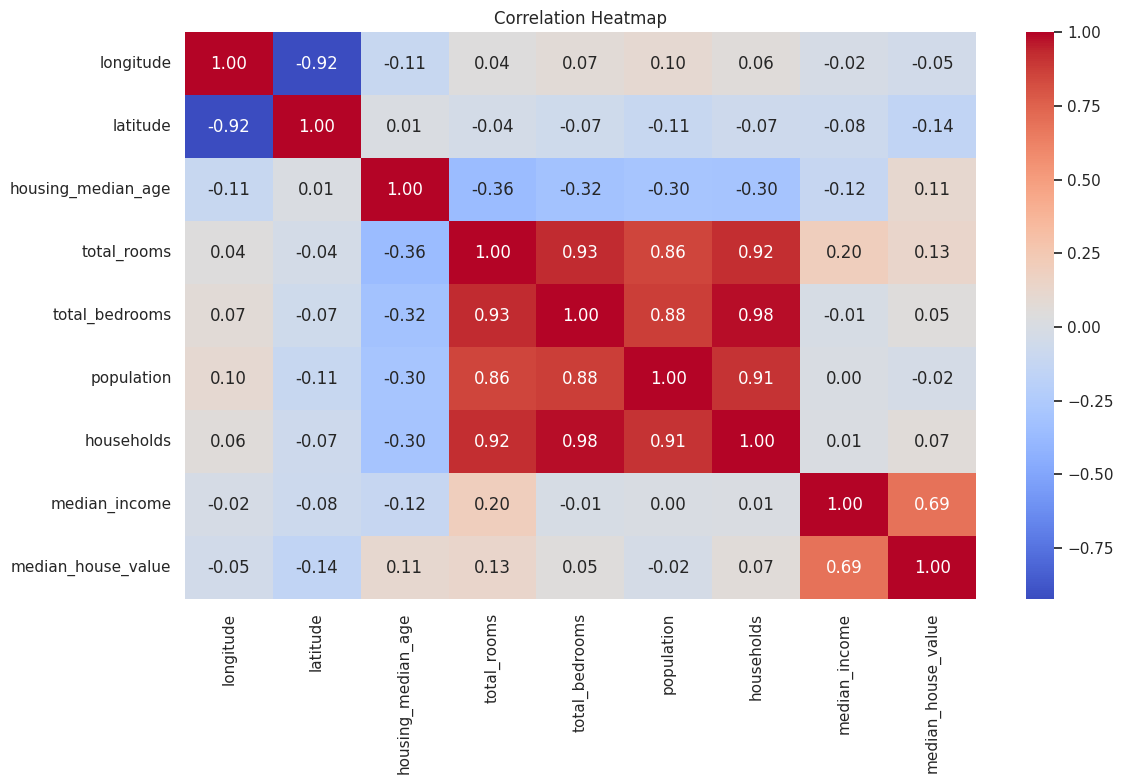

In [8]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nCategorical distribution:\n", df["ocean_proximity"].value_counts())

plt.figure(figsize=(12, 8))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X = df.drop(columns=["median_house_value"]).copy()
y = df["median_house_value"].copy()

# Feature engineering: meaningful ratios
X["rooms_per_household"] = X["total_rooms"] / X["households"].replace(0, np.nan)
X["bedrooms_per_room"] = X["total_bedrooms"] / X["total_rooms"].replace(0, np.nan)
X["population_per_household"] = X["population"] / X["households"].replace(0, np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(
        degree=2, interaction_only=True, include_bias=False
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", len(numeric_features))
print("Categorical features:", categorical_features)
print("Training and test sets ready!")

Numeric features: 11
Categorical features: ['ocean_proximity']
Training and test sets ready!


In [15]:
ols = Pipeline([
    ("preprocessor", preprocessor),
    ("variance", VarianceThreshold()),
    ("model", LinearRegression())
])

ridge = Pipeline([
    ("preprocessor", preprocessor),
    ("variance", VarianceThreshold()),
    ("model", Ridge())
])

lasso = Pipeline([
    ("preprocessor", preprocessor),
    ("variance", VarianceThreshold()),
    ("model", Lasso(max_iter=20000))
])

ols.fit(X_train, y_train)
ols_pred = ols.predict(X_test)

param_grid = {"model__alpha": [0.01, 0.1, 1, 10, 100]}

ridge_search = GridSearchCV(
    ridge, param_grid, cv=3,
    scoring="neg_root_mean_squared_error", n_jobs=2
)
ridge_search.fit(X_train, y_train)
ridge_pred = ridge_search.predict(X_test)

lasso_search = GridSearchCV(
    lasso, param_grid, cv=3,
    scoring="neg_root_mean_squared_error", n_jobs=2
)
lasso_search.fit(X_train, y_train)
lasso_pred = lasso_search.predict(X_test)

print("Best Ridge parameters:", ridge_search.best_params_)
print("Best Lasso parameters:", lasso_search.best_params_)

Best Ridge parameters: {'model__alpha': 100}
Best Lasso parameters: {'model__alpha': 100}


In [16]:
predictions = {
    "OLS": ols_pred,
    "Ridge": ridge_pred,
    "Lasso": lasso_pred
}

results = pd.DataFrame([
    {
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    }
    for name, pred in predictions.items()
]).sort_values("RMSE")

display(results.round(2))

,Model,RMSE,MAE,R2
2,Lasso,66504.97,47484.97,0.66
1,Ridge,66506.90,47496.77,0.66
0,OLS,179952.04,69788.74,-1.47


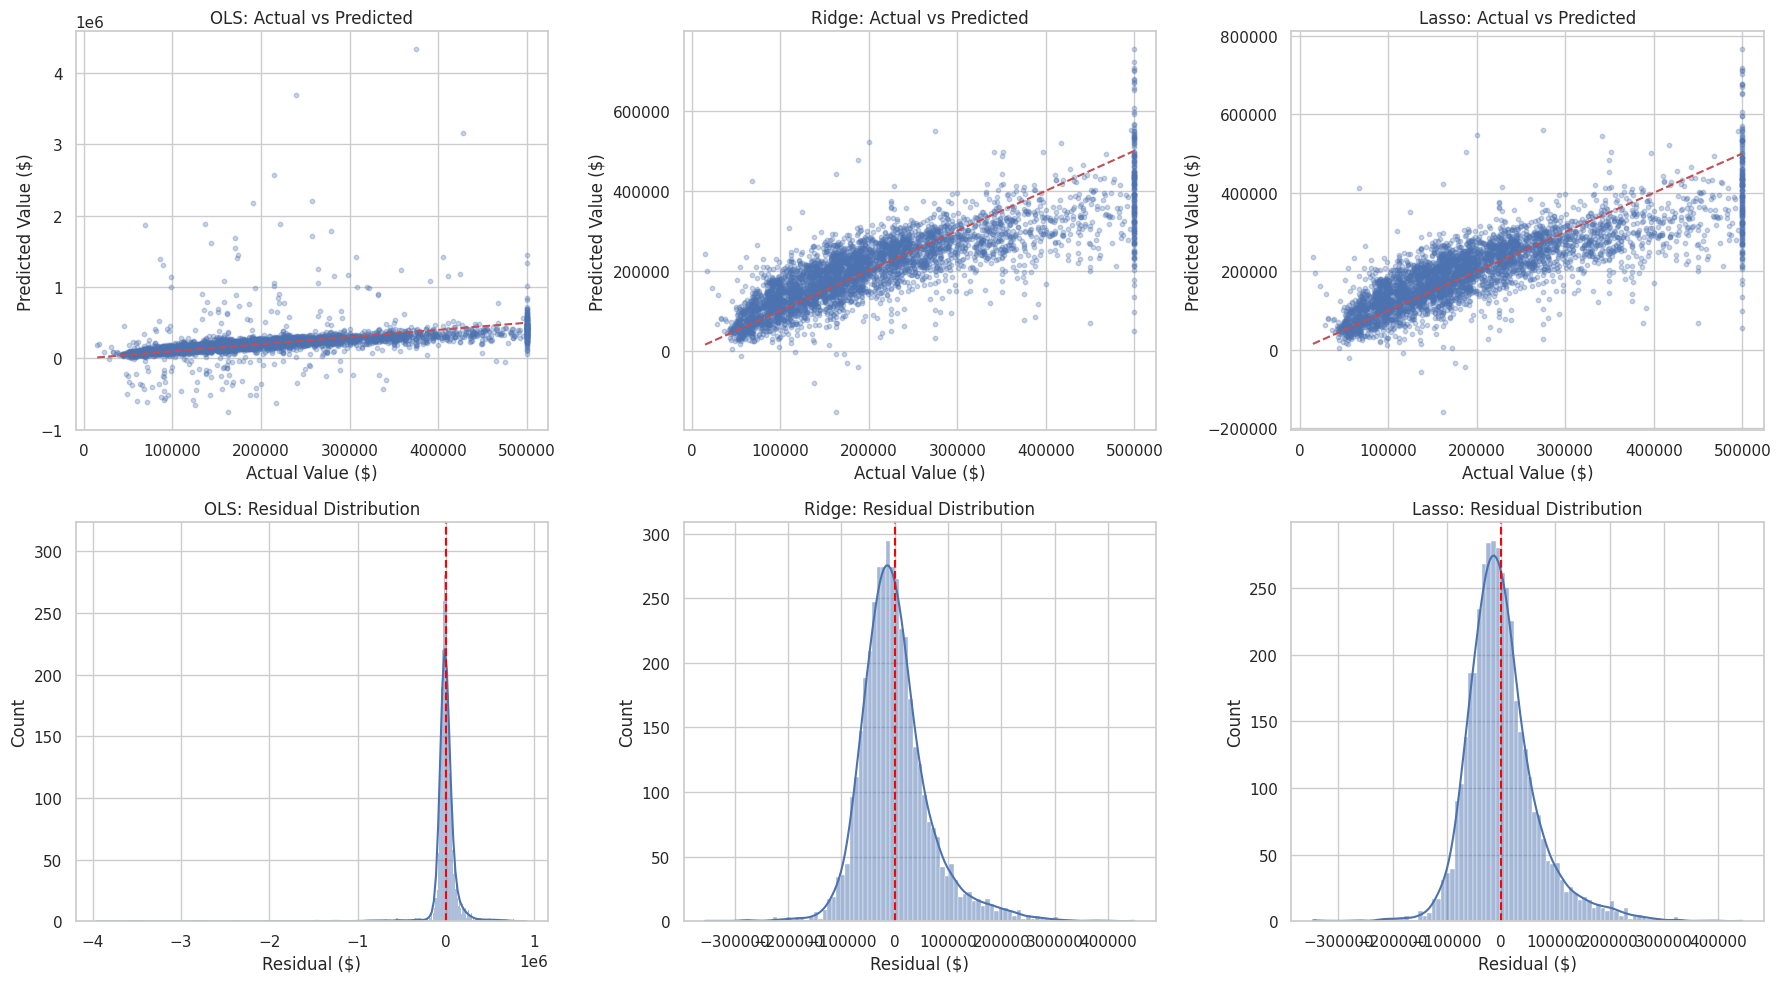

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, (name, pred) in enumerate(predictions.items()):
    axes[0, i].scatter(y_test, pred, alpha=0.3, s=10)
    axes[0, i].plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--"
    )
    axes[0, i].set_title(f"{name}: Actual vs Predicted")
    axes[0, i].set_xlabel("Actual Value ($)")
    axes[0, i].set_ylabel("Predicted Value ($)")

    residuals = y_test - pred
    sns.histplot(residuals, kde=True, ax=axes[1, i])
    axes[1, i].axvline(0, color="red", linestyle="--")
    axes[1, i].set_title(f"{name}: Residual Distribution")
    axes[1, i].set_xlabel("Residual ($)")

plt.tight_layout()
plt.show()